# HPV Data analysis

This file covers the data analysis for the paper "Lymphatic Spread Patterns in HPV+ vs. HPV- Oropharyngeal Squamous Cell Carcinoma: A Multi-Center European Analysis" all numbers and figures reported in the pape and in the thesis are covered here

Load data and plot olors

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lydata as ly
data_combined = pd.read_csv('data/HPV_data_full.csv',header = [0,1,2], index_col=0)
data_combined = data_combined.loc[~(data_combined.ly.t_stage == 0)]
usz_blue = '#005ea8'
usz_green = '#00afa5'
usz_red = '#ae0060'
usz_orange = '#f17900'
usz_gray = '#c5d5db'
data_combined_reduced = data_combined.drop(columns = 'max_llh')

We first need to calculate the clinical consensus. The lydata package provides function for that.

In [31]:
all_modalities = ly.utils.get_default_modalities()
# Select only clinical modalities from all_modalities
clinical_subset = {k: v for k, v in all_modalities.items() if k in ['CT', 'MRI', 'PET', 'diagnostic_consensus', 'pCT']}
data_combined.ly.get_modalities()

['max_llh',
 'CT',
 'FNA',
 'MRI',
 'PET',
 'diagnostic_consensus',
 'metadata',
 'pCT',
 'pathology']

In [32]:
reduced_extended = data_combined_reduced.ly.enhance(clinical_subset)

In [33]:
clinical_consensus = reduced_extended['max_llh'].copy()

# Create the new column structure for data_combined
# We need to rename the columns to have 'clinical_consensus' as the top level
new_columns = pd.MultiIndex.from_tuples([('clinical_consensus', col[0], col[1]) 
                                        for col in clinical_consensus.columns])
clinical_consensus.columns = new_columns

# Now assign to data_combined
for col in new_columns:
    data_combined[col] = clinical_consensus[col]

## Some standard overview

In [34]:
data_combined.ly.max_llh.ipsi.apply(lambda x: pd.Series(x).value_counts())

,I,Ia,Ib,II,IIa,IIb,III,IV,V,Va,Vb,VI,VII,VIII,IX,X
False,704,774,706,205,216,376,526,706,719,721,727,NaN,577,NaN,NaN,NaN
True,76,5,73,575,325,165,254,74,61,11,5,NaN,52,NaN,NaN,NaN


In [35]:
data_combined['tumor','core','t_stage'].value_counts()

(tumor, core, t_stage)
2    272
1    178
4    174
3    156
Name: count, dtype: int64

In [36]:
data_combined.ly.clinical_consensus.ipsi.apply(lambda x: pd.Series(x).value_counts())

,I,Ia,Ib,II,IIa,IIb,III,IV,V,Va,Vb,VI,VII,VIII,IX,X
False,646,733,648,187,197,350,487,629,680,682,686,NaN,577,NaN,NaN,NaN
True,66,5,65,514,332,179,217,72,28,10,6,NaN,51,NaN,NaN,NaN


If needed one can use the center specific datasets for analyses

In [37]:
clb = data_combined.loc[data_combined['patient','core','institution'] == 'Centre Léon Bérard']
hvh = data_combined.loc[data_combined['patient','core','institution'] == "Vall d'Hebron Barcelona Hospital"]
usz = data_combined.loc[data_combined['patient','core','institution'] == 'University Hospital Zurich']

First we produce the general overview table

In [38]:
def create_complete_involvement_table_max_llh(data):
    """
    Create complete involvement table for LaTeX from max_llh diagnosis data.
    
    Groups:
    - T1/T2 vs T3/T4 (stratified by HPV)
    - T1/T2, T3/T4 (regardless of HPV)
    - HPV+, HPV- (regardless of T-stage)
    - Lymph node levels: I, II, III, IV, V, VII
    - Uses max_llh diagnosis data (both ipsi and contra combined)
    """
    
    # Define lymph node levels of interest
    levels = ['I', 'II', 'III', 'IV', 'V', 'VII']
    

    
    # Create working dataframe with the columns we need
    working_df = pd.DataFrame({
        'hpv_status': data.ly.hpv,
        't_stage': data.ly.t_stage
    })
    
    for level in levels:
        working_df[level] = data.ly.max_llh.ipsi[level]

    
    working_df = working_df[working_df['t_stage'] >= 0] 
    working_df['t_stage_group'] = working_df['t_stage'].apply(
        lambda x: 'T1/T2' if x in [0, 1, 2] else 'T3/T4' if x in [3, 4] else 'Other'
    )
    
    # Remove any 'Other' categories
    working_df = working_df[working_df['t_stage_group'] != 'Other']
    
    # Helper function to create a row
    def create_row(subset, group_name):
        if len(subset) == 0:
            row = {'Group': group_name, 'Total': 0}
            for level in levels:
                row[f'Level_{level}'] = '0 (0%)'
            return row
        total_patients = subset[['I','II','III','IV','V','VII']].notna().sum()
        row = {'Group': group_name, 'Total': len(subset)}
        
        for level in levels:
            involved = subset[level].sum()
            percentage = (involved / total_patients[level] * 100) if total_patients[level] > 0 else 0
            row[f'Level_{level}'] = f'{involved} & {percentage:.1f}\%'
        
        return row
    
    # Create the results table
    results = []
    
    # 2. Add T1/T2 and T3/T4 (regardless of HPV status)
    for t_group in ['T1/T2', 'T3/T4']:
        mask = working_df['t_stage_group'] == t_group
        subset = working_df[mask]
        results.append(create_row(subset, f'{t_group}'))
    
    # 3. Add HPV+ and HPV- (regardless of T-stage)
    for hpv_status in [True, False]:
        hpv_label = 'HPV+' if hpv_status else 'HPV-'
        mask = working_df['hpv_status'] == hpv_status
        subset = working_df[mask]
        results.append(create_row(subset, f'{hpv_label}'))

    # 1. T1/T2 and T3/T4 stratified by HPV status
    for t_group in ['T1/T2', 'T3/T4']:
        for hpv_status in [True, False]:
            hpv_label = 'HPV+' if hpv_status else 'HPV-'
            mask = (working_df['t_stage_group'] == t_group) & (working_df['hpv_status'] == hpv_status)
            subset = working_df[mask]
            results.append(create_row(subset, f'{t_group} {hpv_label}'))
    
    # Convert to DataFrame for easy viewing
    results_df = pd.DataFrame(results)
    
    return results_df

# Test the complete function
try:
    complete_involvement_table = create_complete_involvement_table_max_llh(data_combined)    
    print("\n\nLaTeX Format:")
    print("="*65)
    for _, row in complete_involvement_table.iterrows():
        latex_row = f"{row['Group']} & {row['Total']} & {row['Level_I']} & {row['Level_II']} & {row['Level_III']} & {row['Level_IV']} & {row['Level_V']} & {row['Level_VII']} \\\\"
        print(latex_row)
        
except Exception as e:
    print(f"Error: {e}")
    import traceback
    traceback.print_exc()



LaTeX Format:
T1/T2 & 450 & 21 & 4.7\% & 320 & 71.1\% & 123 & 27.3\% & 35 & 7.8\% & 29 & 6.4\% & 20 & 5.9\% \\
T3/T4 & 330 & 55 & 16.7\% & 255 & 77.3\% & 131 & 39.7\% & 39 & 11.8\% & 32 & 9.7\% & 32 & 11.0\% \\
HPV+ & 456 & 37 & 8.1\% & 372 & 81.6\% & 154 & 33.8\% & 42 & 9.2\% & 40 & 8.8\% & 27 & 7.6\% \\
HPV- & 324 & 39 & 12.0\% & 203 & 62.7\% & 100 & 30.9\% & 32 & 9.9\% & 21 & 6.5\% & 25 & 9.1\% \\
T1/T2 HPV+ & 284 & 12 & 4.2\% & 229 & 80.6\% & 86 & 30.3\% & 21 & 7.4\% & 22 & 7.7\% & 13 & 6.3\% \\
T1/T2 HPV- & 166 & 9 & 5.4\% & 91 & 54.8\% & 37 & 22.3\% & 14 & 8.4\% & 7 & 4.2\% & 7 & 5.3\% \\
T3/T4 HPV+ & 172 & 25 & 14.5\% & 143 & 83.1\% & 68 & 39.5\% & 21 & 12.2\% & 18 & 10.5\% & 14 & 9.6\% \\
T3/T4 HPV- & 158 & 30 & 19.0\% & 112 & 70.9\% & 63 & 39.9\% & 18 & 11.4\% & 14 & 8.9\% & 18 & 12.4\% \\


<>:49: SyntaxWarning: invalid escape sequence '\%'
<>:49: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_23176/3076344924.py:49: SyntaxWarning: invalid escape sequence '\%'
  row[f'Level_{level}'] = f'{involved} & {percentage:.1f}\%'


## Plotting HPV involvement

In [39]:
from statsmodels.stats.proportion import proportion_confint

def involvement_plotter_HPV_with_CI(dataset, diagnostic_mod='max_llh', side='ipsi', display='percentage', LABELS=["I", "II", "III", "IV", "V", "VII"], print_summary=True, split_by='t_stage', show_ci=True, upper_limit=100, save_as=None, title = None):
    """
    Enhanced involvement plotter with optional 95% confidence intervals displayed as error bars.
    """
    WIDTH, SPACE = 1, 1.5
    available_levels = list(np.intersect1d(LABELS, dataset[diagnostic_mod][side].columns))
    LABELS = available_levels
    WIDTHS = np.ones(len(available_levels)) * WIDTH
    POSITIONS = np.array([np.sum(WIDTHS[0:i]) + i * SPACE for i in range(len(WIDTHS))])
    
    # initialize figure
    fig = plt.figure(figsize=(10, 5))
    t_stages = dataset.ly.t_stage
    hpv_status = dataset.ly.hpv
    extension = dataset['tumor', 'core', 'extension']
    
    if split_by == 't_stage':
        group1_mask = t_stages <= 2
        group2_mask = t_stages > 2
        group1_label = 'T1/T2'
        group2_label = 'T3/T4'
        group1_title = 'T1 & T2'
        group2_title = 'T3 & T4'
        split_title = 'T-stage'
    elif split_by == 'extension':
        valid_extension = extension.notna()
        group1_mask = valid_extension & (extension == True)
        group2_mask = valid_extension & (extension == False)
        group1_label = 'Extension: True'
        group2_label = 'Extension: False'
        group1_title = 'Extension = True'
        group2_title = 'Extension = False'
        split_title = 'midline extension'
    else:
        raise ValueError("split_by must be 't_stage' or 'extension'")

    ci_title = 'with 95% CI' if show_ci else ''
    capsize = 5 if show_ci else 0
    error_kwargs = {'linewidth': 2, 'ecolor': 'black'} if show_ci else None

    # define grid layout
    gs = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, wspace=0.075, hspace=0.4)
    ax = {}

    # define axes to plot on
    ax["early"] = fig.add_subplot(gs[0, 0])
    ax["late"] = fig.add_subplot(gs[0, 1])
    
    # Initialize summary data structure
    summary_data = []
    
    # ===== GROUP 1 DATA =====
    num_HPVpos_early = len(dataset.loc[(hpv_status == True) & group1_mask])
    num_HPVneg_early = len(dataset.loc[(hpv_status == False) & group1_mask])
    
    # Calculate percentages
    ipsi_HPVpos_early = (100 / (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == True) & group1_mask].sum()) * (
        dataset[diagnostic_mod][side] == True
    ).loc[(hpv_status == True) & group1_mask].sum()
    ipsi_HPVneg_early = (100 / (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == False) & group1_mask].sum()) * (
        dataset[diagnostic_mod][side] == True
    ).loc[(hpv_status == False) & group1_mask].sum()
    
    # Calculate confidence intervals for group 1
    ci_HPVpos_early = {}
    ci_HPVneg_early = {}
    yerr_HPVpos_early = [[], []] if show_ci else None  # [lower errors, upper errors]
    yerr_HPVneg_early = [[], []] if show_ci else None
    
    for label in LABELS:
        # HPV+ group 1
        successes_pos = (dataset[diagnostic_mod][side] == True).loc[(hpv_status == True) & group1_mask].sum()[label]
        total_pos = (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == True) & group1_mask].sum()[label]
        point_est_pos = ipsi_HPVpos_early[label]
        if show_ci:
            lower_pos, upper_pos = proportion_confint(count=successes_pos, nobs=total_pos, alpha=0.05, method='wilson')
            lower_pos *= 100
            upper_pos *= 100
            ci_HPVpos_early[label] = (lower_pos, upper_pos)
            yerr_HPVpos_early[0].append(point_est_pos - lower_pos)  # lower error
            yerr_HPVpos_early[1].append(upper_pos - point_est_pos)  # upper error
            ci_text_pos = f'({lower_pos:.1f}%, {upper_pos:.1f}%)'
        else:
            ci_text_pos = 'N/A'
        
        # Add to summary
        summary_data.append({
            'Stage': group1_label,
            'HPV': 'HPV+',
            'Level': label,
            'n': f'{successes_pos}/{total_pos}',
            'Percentage': f'{point_est_pos:.1f}%',
            '95% CI': ci_text_pos,
        })
        
        # HPV- group 1
        successes_neg = (dataset[diagnostic_mod][side] == True).loc[(hpv_status == False) & group1_mask].sum()[label]
        total_neg = (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == False) & group1_mask].sum()[label]
        point_est_neg = ipsi_HPVneg_early[label]
        if show_ci:
            lower_neg, upper_neg = proportion_confint(count=successes_neg, nobs=total_neg, alpha=0.05, method='wilson')
            lower_neg *= 100
            upper_neg *= 100
            ci_HPVneg_early[label] = (lower_neg, upper_neg)
            yerr_HPVneg_early[0].append(point_est_neg - lower_neg)
            yerr_HPVneg_early[1].append(upper_neg - point_est_neg)
            ci_text_neg = f'({lower_neg:.1f}%, {upper_neg:.1f}%)'
        else:
            ci_text_neg = 'N/A'
        
        # Add to summary
        summary_data.append({
            'Stage': group1_label,
            'HPV': 'HPV-',
            'Level': label,
            'n': f'{successes_neg}/{total_neg}',
            'Percentage': f'{point_est_neg:.1f}%',
            '95% CI': ci_text_neg,
        })
    
    # Plot group 1 data with error bars
    bars1 = ax["early"].bar(
        POSITIONS,
        ipsi_HPVpos_early[LABELS],
        label=f"HPV+ ({num_HPVpos_early})",
        width=WIDTHS,
        yerr=yerr_HPVpos_early if show_ci else None,
        capsize=capsize,
        error_kw=error_kwargs
    )
    bars2 = ax["early"].bar(
        POSITIONS - SPACE / 2.,
        ipsi_HPVneg_early[LABELS],
        label=f"HPV- ({num_HPVneg_early})",
        width=WIDTHS,
        yerr=yerr_HPVneg_early if show_ci else None,
        capsize=capsize,
        error_kw=error_kwargs
    )
    
    # Add text labels
    for i, bar in enumerate(bars1):
        height = bar.get_height()
        if display == 'percentage':
            text = f'{height:.1f}%'
        else:
            text = str((dataset[diagnostic_mod][side] == True).loc[(hpv_status == True) & group1_mask].sum()[LABELS[i]])
        # Place text above error bar
        upper_err = yerr_HPVpos_early[1][i] if show_ci else 0
        ax["early"].text(bar.get_x() + bar.get_width() / 2, height + upper_err + 2, text, ha='center', fontsize=10)
    
    for i, bar in enumerate(bars2):
        height = bar.get_height()
        if display == 'percentage':
            text = f'{height:.1f}%'
        else:
            text = str((dataset[diagnostic_mod][side] == True).loc[(hpv_status == False) & group1_mask].sum()[LABELS[i]])
        upper_err = yerr_HPVneg_early[1][i] if show_ci else 0
        ax["early"].text(bar.get_x() + bar.get_width() / 2, height + upper_err + 2, text, ha='center', fontsize=10)
    
    ax["early"].set_xticks(POSITIONS - SPACE / 2.)
    ax["early"].set_xticklabels(LABELS)
    ax["early"].set_ylabel("overall involvement [%]")
    ax["early"].grid(axis='y', alpha=0.3)
    ax["early"].set_ylim([0, upper_limit])
    ax["early"].set_title(group1_title)
    ax["early"].legend()
    
    # ===== GROUP 2 DATA =====
    num_HPVpos_late = len(dataset.loc[(hpv_status == True) & group2_mask])
    num_HPVneg_late = len(dataset.loc[(hpv_status == False) & group2_mask])
    
    # Calculate percentages
    ipsi_HPVpos_late = (100 / (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == True) & group2_mask].sum()) * (
        dataset[diagnostic_mod][side] == True
    ).loc[(hpv_status == True) & group2_mask].sum()
    ipsi_HPVneg_late = (100 / (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == False) & group2_mask].sum()) * (
        dataset[diagnostic_mod][side] == True
    ).loc[(hpv_status == False) & group2_mask].sum()
    
    # Calculate confidence intervals for group 2
    ci_HPVpos_late = {}
    ci_HPVneg_late = {}
    yerr_HPVpos_late = [[], []] if show_ci else None
    yerr_HPVneg_late = [[], []] if show_ci else None
    
    for label in LABELS:
        # HPV+ group 2
        successes_pos = (dataset[diagnostic_mod][side] == True).loc[(hpv_status == True) & group2_mask].sum()[label]
        total_pos = (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == True) & group2_mask].sum()[label]
        point_est_pos = ipsi_HPVpos_late[label]
        if show_ci:
            lower_pos, upper_pos = proportion_confint(count=successes_pos, nobs=total_pos, alpha=0.05, method='wilson')
            lower_pos *= 100
            upper_pos *= 100
            ci_HPVpos_late[label] = (lower_pos, upper_pos)
            yerr_HPVpos_late[0].append(point_est_pos - lower_pos)
            yerr_HPVpos_late[1].append(upper_pos - point_est_pos)
            ci_text_pos = f'({lower_pos:.1f}%, {upper_pos:.1f}%)'
        else:
            ci_text_pos = 'N/A'
        
        # Add to summary
        summary_data.append({
            'Stage': group2_label,
            'HPV': 'HPV+',
            'Level': label,
            'n': f'{successes_pos}/{total_pos}',
            'Percentage': f'{point_est_pos:.1f}%',
            '95% CI': ci_text_pos,
        })
        
        # HPV- group 2
        successes_neg = (dataset[diagnostic_mod][side] == True).loc[(hpv_status == False) & group2_mask].sum()[label]
        total_neg = (dataset[diagnostic_mod][side].notna()).loc[(hpv_status == False) & group2_mask].sum()[label]
        point_est_neg = ipsi_HPVneg_late[label]
        if show_ci:
            lower_neg, upper_neg = proportion_confint(count=successes_neg, nobs=total_neg, alpha=0.05, method='wilson')
            lower_neg *= 100
            upper_neg *= 100
            ci_HPVneg_late[label] = (lower_neg, upper_neg)
            yerr_HPVneg_late[0].append(point_est_neg - lower_neg)
            yerr_HPVneg_late[1].append(upper_neg - point_est_neg)
            ci_text_neg = f'({lower_neg:.1f}%, {upper_neg:.1f}%)'
        else:
            ci_text_neg = 'N/A'
        
        # Add to summary
        summary_data.append({
            'Stage': group2_label,
            'HPV': 'HPV-',
            'Level': label,
            'n': f'{successes_neg}/{total_neg}',
            'Percentage': f'{point_est_neg:.1f}%',
            '95% CI': ci_text_neg,
        })
    
    # Plot group 2 data with error bars
    bars3 = ax["late"].bar(
        POSITIONS,
        ipsi_HPVpos_late[LABELS],
        label=f"HPV+ ({num_HPVpos_late})",
        width=WIDTHS,
        yerr=yerr_HPVpos_late if show_ci else None,
        capsize=capsize,
        error_kw=error_kwargs
    )
    bars4 = ax["late"].bar(
        POSITIONS - SPACE / 2.,
        ipsi_HPVneg_late[LABELS],
        label=f"HPV- ({num_HPVneg_late})",
        width=WIDTHS,
        yerr=yerr_HPVneg_late if show_ci else None,
        capsize=capsize,
        error_kw=error_kwargs
    )
    
    # Add text labels
    for i, bar in enumerate(bars3):
        height = bar.get_height()
        if display == 'percentage':
            text = f'{height:.1f}%'
        else:
            text = str((dataset[diagnostic_mod][side] == True).loc[(hpv_status == True) & group2_mask].sum()[LABELS[i]])
        upper_err = yerr_HPVpos_late[1][i] if show_ci else 0
        ax["late"].text(bar.get_x() + bar.get_width() / 2, height + upper_err + 2, text, ha='center', fontsize=10)
    
    for i, bar in enumerate(bars4):
        height = bar.get_height()
        if display == 'percentage':
            text = f'{height:.1f}%'
        else:
            text = str((dataset[diagnostic_mod][side] == True).loc[(hpv_status == False) & group2_mask].sum()[LABELS[i]])
        upper_err = yerr_HPVneg_late[1][i] if show_ci else 0
        ax["late"].text(bar.get_x() + bar.get_width() / 2, height + upper_err + 2, text, ha='center', fontsize=10)
    
    ax["late"].set_xticks(POSITIONS - SPACE / 2.)
    ax["late"].set_xticklabels(LABELS)
    ax["late"].grid(axis='y', alpha=0.3)
    ax["late"].set_ylim([0, upper_limit])
    plt.setp(ax["late"].get_yticklabels(), visible=False)
    ax["late"].set_title(group2_title)
    ax["late"].legend()
    
    # Labeling the subplots
    ax["early"].annotate("a)", (0.04, 0.92), xycoords="axes fraction")
    ax["late"].annotate("b)", (0.04, 0.92), xycoords="axes fraction")
    if title is None:
        fig.suptitle(f'Lymph node involvement in HPV+ and HPV- patients ({side}lateral) by {split_title} {ci_title}', fontsize=16)
    else:
        fig.suptitle(title, fontsize=16)

    if save_as:
        fig.savefig(save_as, dpi=300, bbox_inches='tight')

    plt.show()
    
    # Print summary table if requested
    if print_summary:
        summary_df = pd.DataFrame(summary_data)
        print(f"\n{'='*90}")
        print(f"SUMMARY: {side.upper()}LATERAL Lymph Node Involvement {ci_title}")
        print(f"Diagnostic modality: {diagnostic_mod}")
        print(f"Split by: {split_title}")
        print(f"{'='*90}\n")
        print(summary_df.to_string(index=False))
        print(f"\n{'='*90}\n")
        
        return summary_df
    
    return None


# Example usage:
# summary = involvement_plotter_HPV_with_CI(data_combined, 'max_llh', display='percentage', side='ipsi')
# summary = involvement_plotter_HPV_with_CI(data_combined, 'max_llh', display='percentage', side='ipsi', split_by='extension')
# summary = involvement_plotter_HPV_with_CI(data_combined, 'max_llh', display='percentage', side='ipsi', split_by='extension', show_ci=False)
# summary = involvement_plotter_HPV_with_CI(data_combined, 'max_llh', display='percentage', side='ipsi', split_by='extension', show_ci=False, save_as='extension_no_ci.png')

A simple plot of HPV+ vs HPV-. Can be adjusted on diagnose type and dataset

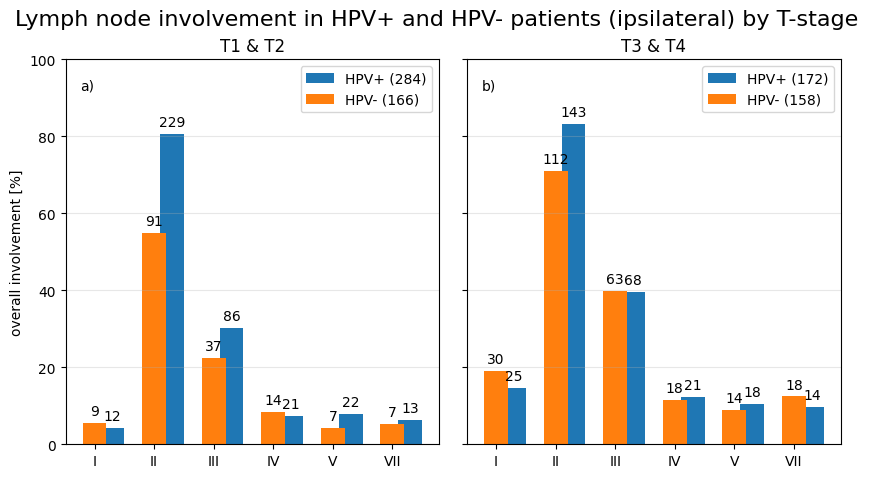


SUMMARY: IPSILATERAL Lymph Node Involvement 
Diagnostic modality: max_llh
Split by: T-stage

Stage  HPV Level       n Percentage 95% CI
T1/T2 HPV+     I  12/284       4.2%    N/A
T1/T2 HPV-     I   9/166       5.4%    N/A
T1/T2 HPV+    II 229/284      80.6%    N/A
T1/T2 HPV-    II  91/166      54.8%    N/A
T1/T2 HPV+   III  86/284      30.3%    N/A
T1/T2 HPV-   III  37/166      22.3%    N/A
T1/T2 HPV+    IV  21/284       7.4%    N/A
T1/T2 HPV-    IV  14/166       8.4%    N/A
T1/T2 HPV+     V  22/284       7.7%    N/A
T1/T2 HPV-     V   7/166       4.2%    N/A
T1/T2 HPV+   VII  13/207       6.3%    N/A
T1/T2 HPV-   VII   7/131       5.3%    N/A
T3/T4 HPV+     I  25/172      14.5%    N/A
T3/T4 HPV-     I  30/158      19.0%    N/A
T3/T4 HPV+    II 143/172      83.1%    N/A
T3/T4 HPV-    II 112/158      70.9%    N/A
T3/T4 HPV+   III  68/172      39.5%    N/A
T3/T4 HPV-   III  63/158      39.9%    N/A
T3/T4 HPV+    IV  21/172      12.2%    N/A
T3/T4 HPV-    IV  18/158      11.4%    N/A
T3/

,Stage,HPV,Level,n,Percentage,95% CI
0,T1/T2,HPV+,I,12/284,4.2%,N/A
1,T1/T2,HPV-,I,9/166,5.4%,N/A
2,T1/T2,HPV+,II,229/284,80.6%,N/A
3,T1/T2,HPV-,II,91/166,54.8%,N/A
4,T1/T2,HPV+,III,86/284,30.3%,N/A
5,T1/T2,HPV-,III,37/166,22.3%,N/A
6,T1/T2,HPV+,IV,21/284,7.4%,N/A
7,T1/T2,HPV-,IV,14/166,8.4%,N/A
8,T1/T2,HPV+,V,22/284,7.7%,N/A
9,T1/T2,HPV-,V,7/166,4.2%,N/A


In [40]:
involvement_plotter_HPV_with_CI(data_combined, 'max_llh', display = 'none', side = 'ipsi', show_ci = False, upper_limit = 100, save_as = 'figures/involvement_diagnostic') 


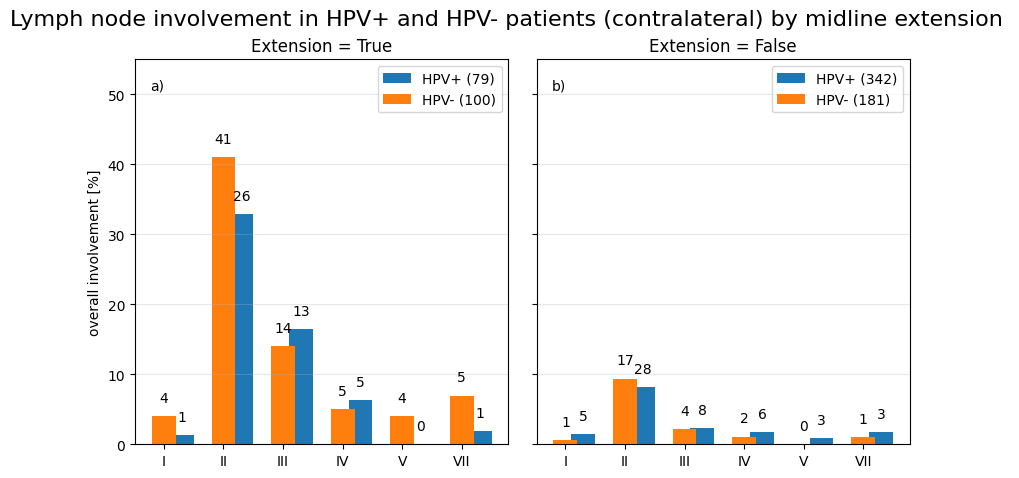


SUMMARY: CONTRALATERAL Lymph Node Involvement 
Diagnostic modality: max_llh
Split by: midline extension

           Stage  HPV Level      n Percentage 95% CI
 Extension: True HPV+     I   1/79       1.3%    N/A
 Extension: True HPV-     I  4/100       4.0%    N/A
 Extension: True HPV+    II  26/79      32.9%    N/A
 Extension: True HPV-    II 41/100      41.0%    N/A
 Extension: True HPV+   III  13/79      16.5%    N/A
 Extension: True HPV-   III 14/100      14.0%    N/A
 Extension: True HPV+    IV   5/79       6.3%    N/A
 Extension: True HPV-    IV  5/100       5.0%    N/A
 Extension: True HPV+     V   0/79       0.0%    N/A
 Extension: True HPV-     V  4/100       4.0%    N/A
 Extension: True HPV+   VII   1/54       1.9%    N/A
 Extension: True HPV-   VII   5/72       6.9%    N/A
Extension: False HPV+     I  5/342       1.5%    N/A
Extension: False HPV-     I  1/181       0.6%    N/A
Extension: False HPV+    II 28/342       8.2%    N/A
Extension: False HPV-    II 17/181       9.4% 

,Stage,HPV,Level,n,Percentage,95% CI
0,Extension: True,HPV+,I,1/79,1.3%,N/A
1,Extension: True,HPV-,I,4/100,4.0%,N/A
2,Extension: True,HPV+,II,26/79,32.9%,N/A
3,Extension: True,HPV-,II,41/100,41.0%,N/A
4,Extension: True,HPV+,III,13/79,16.5%,N/A
5,Extension: True,HPV-,III,14/100,14.0%,N/A
6,Extension: True,HPV+,IV,5/79,6.3%,N/A
7,Extension: True,HPV-,IV,5/100,5.0%,N/A
8,Extension: True,HPV+,V,0/79,0.0%,N/A
9,Extension: True,HPV-,V,4/100,4.0%,N/A


In [41]:
involvement_plotter_HPV_with_CI(data_combined, 'max_llh', display = None, side='contra', show_ci = False, split_by = 'extension',upper_limit = 55, save_as='figures/involvement_diagnostic_contra_extension')


## Involvement Pattern analysis

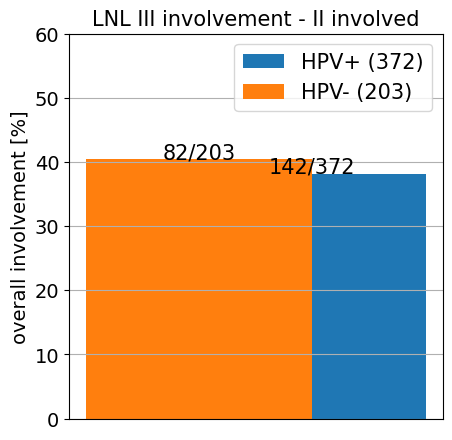

In [42]:
dataset = data_combined.loc[data_combined['max_llh']['ipsi']['II'] == True]
diagnostic_mod='max_llh'
display='none'
LABELS = ["III"]
WIDTH, SPACE = 0.8, 0.8
available_levels = list(np.intersect1d(LABELS, dataset[diagnostic_mod]['ipsi'].columns))
LABELS = available_levels
WIDTHS  = np.ones(len(available_levels)) * WIDTH
POSITIONS = np.array([np.sum(WIDTHS[0:i]) + i * SPACE for i in range(len(WIDTHS))])

# initialize figure
fig = plt.figure(figsize=(10, 5))
t_stages = dataset.ly.t_stage
hpv_status = dataset.ly.hpv

# define grid layout
gs = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, wspace=0.075, hspace=0.4)
ax = {}

# define axes to plot on
ax["early"] = fig.add_subplot(gs[0, 0])

# Early stage data
num_HPVpos = len(dataset.loc[(hpv_status == True)])
num_HPVneg = len(dataset.loc[(hpv_status == False)])

ipsi_HPVpos = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == True)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == True) ].sum()
ipsi_HPVneg = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == False)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == False)].sum()

# Plot early stage data
bars1 = ax["early"].bar(
    POSITIONS,
    ipsi_HPVpos[LABELS],
    label=f"HPV+ ({num_HPVpos})",
    width=WIDTHS
)
bars2 = ax["early"].bar(
    POSITIONS - SPACE / 2.,
    ipsi_HPVneg[LABELS],
    label=f"HPV- ({num_HPVneg})",
    width=WIDTHS
)

for i, bar in enumerate(bars1):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True) ])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

for i, bar in enumerate(bars2):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

ax["early"].set_xticks([])
ax["early"].set_ylabel("overall involvement [%]", fontsize = 14)
ax["early"].grid(axis='y')
ax["early"].set_ylim([0, 60])
ax['early'].tick_params(axis='y', labelsize=14)
ax["early"].set_title('LNL III involvement - II involved', fontsize = 15)
ax["early"].legend(fontsize = 15)

plt.savefig("figures/III_downstream.png", dpi=300, bbox_inches='tight')
plt.show()


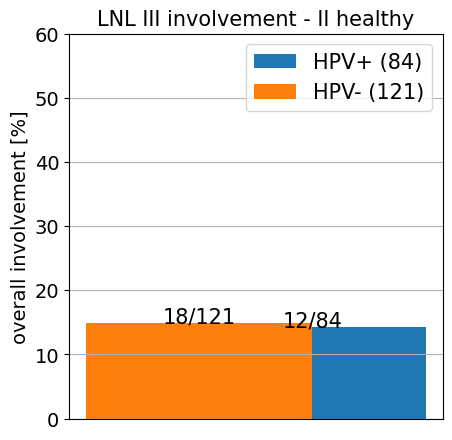

In [43]:
dataset = data_combined.loc[data_combined['max_llh']['ipsi']['II'] == False]
diagnostic_mod='max_llh'
display='none'
LABELS = ["III"]
WIDTH, SPACE = 0.8, 0.8
available_levels = list(np.intersect1d(LABELS, dataset[diagnostic_mod]['ipsi'].columns))
LABELS = available_levels
WIDTHS  = np.ones(len(available_levels)) * WIDTH
POSITIONS = np.array([np.sum(WIDTHS[0:i]) + i * SPACE for i in range(len(WIDTHS))])

# initialize figure
fig = plt.figure(figsize=(10, 5))
t_stages = dataset.ly.t_stage
hpv_status = dataset.ly.hpv

# define grid layout
gs = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, wspace=0.075, hspace=0.4)
ax = {}

# define axes to plot on
ax["early"] = fig.add_subplot(gs[0, 0])

# Early stage data
num_HPVpos = len(dataset.loc[(hpv_status == True)])
num_HPVneg = len(dataset.loc[(hpv_status == False)])

ipsi_HPVpos = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == True)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == True) ].sum()
ipsi_HPVneg = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == False)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == False)].sum()

# Plot early stage data
bars1 = ax["early"].bar(
    POSITIONS,
    ipsi_HPVpos[LABELS],
    label=f"HPV+ ({num_HPVpos})",
    width=WIDTHS
)
bars2 = ax["early"].bar(
    POSITIONS - SPACE / 2.,
    ipsi_HPVneg[LABELS],
    label=f"HPV- ({num_HPVneg})",
    width=WIDTHS
)

for i, bar in enumerate(bars1):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True) ])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

for i, bar in enumerate(bars2):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

ax["early"].set_xticks([])
ax["early"].set_ylabel("overall involvement [%]", fontsize = 14)
ax["early"].grid(axis='y')
ax["early"].set_ylim([0, 60])
ax['early'].tick_params(axis='y', labelsize=14)
ax["early"].set_title('LNL III involvement - II healthy', fontsize = 15)
ax["early"].legend(fontsize = 15)

plt.savefig("figures/III_skip.png", dpi=300, bbox_inches='tight')
plt.show()


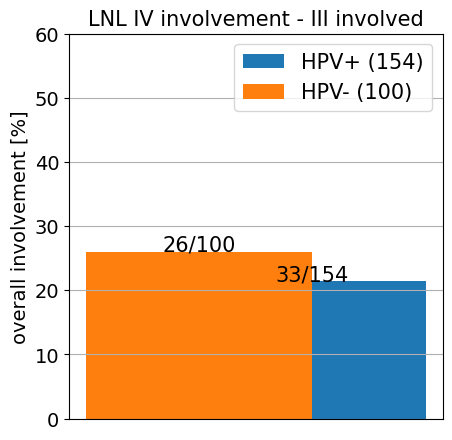

In [44]:
dataset = data_combined.loc[data_combined['max_llh']['ipsi']['III'] == True]
diagnostic_mod='max_llh'
display='none'
LABELS = ["IV"]
WIDTH, SPACE = 0.8, 0.8
available_levels = list(np.intersect1d(LABELS, dataset[diagnostic_mod]['ipsi'].columns))
LABELS = available_levels
WIDTHS  = np.ones(len(available_levels)) * WIDTH
POSITIONS = np.array([np.sum(WIDTHS[0:i]) + i * SPACE for i in range(len(WIDTHS))])

# initialize figure
fig = plt.figure(figsize=(10, 5))
t_stages = dataset.ly.t_stage
hpv_status = dataset.ly.hpv

# define grid layout
gs = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, wspace=0.075, hspace=0.4)
ax = {}

# define axes to plot on
ax["early"] = fig.add_subplot(gs[0, 0])

# Early stage data
num_HPVpos = len(dataset.loc[(hpv_status == True)])
num_HPVneg = len(dataset.loc[(hpv_status == False)])

ipsi_HPVpos = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == True)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == True) ].sum()
ipsi_HPVneg = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == False)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == False)].sum()

# Plot early stage data
bars1 = ax["early"].bar(
    POSITIONS,
    ipsi_HPVpos[LABELS],
    label=f"HPV+ ({num_HPVpos})",
    width=WIDTHS
)
bars2 = ax["early"].bar(
    POSITIONS - SPACE / 2.,
    ipsi_HPVneg[LABELS],
    label=f"HPV- ({num_HPVneg})",
    width=WIDTHS
)

for i, bar in enumerate(bars1):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True) ])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

for i, bar in enumerate(bars2):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

ax["early"].set_xticks([])
ax["early"].set_ylabel("overall involvement [%]", fontsize = 14)
ax["early"].grid(axis='y')
ax["early"].set_ylim([0, 60])
ax['early'].tick_params(axis='y', labelsize=14)
ax["early"].set_title('LNL IV involvement - III involved', fontsize = 15)
ax["early"].legend(fontsize = 15)

plt.savefig("figures/IV_downstream.png", dpi=300, bbox_inches='tight')
plt.show()


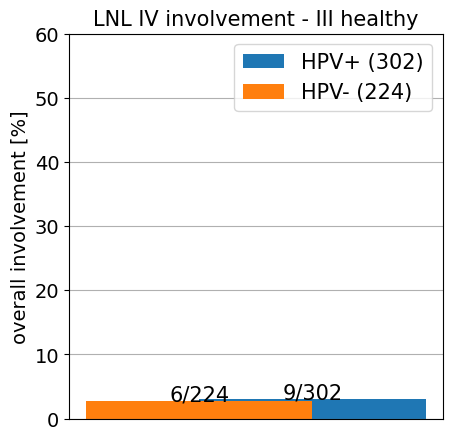

In [45]:
dataset = data_combined.loc[data_combined['max_llh']['ipsi']['III'] == False]
diagnostic_mod='max_llh'
display='none'
LABELS = ["IV"]
WIDTH, SPACE = 0.8, 0.8
available_levels = list(np.intersect1d(LABELS, dataset[diagnostic_mod]['ipsi'].columns))
LABELS = available_levels
WIDTHS  = np.ones(len(available_levels)) * WIDTH
POSITIONS = np.array([np.sum(WIDTHS[0:i]) + i * SPACE for i in range(len(WIDTHS))])

# initialize figure
fig = plt.figure(figsize=(10, 5))
t_stages = dataset.ly.t_stage
hpv_status = dataset.ly.hpv

# define grid layout
gs = gridspec.GridSpec(ncols=2, nrows=1, figure=fig, wspace=0.075, hspace=0.4)
ax = {}

# define axes to plot on
ax["early"] = fig.add_subplot(gs[0, 0])

# Early stage data
num_HPVpos = len(dataset.loc[(hpv_status == True)])
num_HPVneg = len(dataset.loc[(hpv_status == False)])

ipsi_HPVpos = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == True)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == True) ].sum()
ipsi_HPVneg = (100 / (dataset[diagnostic_mod]['ipsi'].notna()).loc[(hpv_status == False)].sum()) * (
    dataset[diagnostic_mod]['ipsi'] == True
).loc[(hpv_status == False)].sum()

# Plot early stage data
bars1 = ax["early"].bar(
    POSITIONS,
    ipsi_HPVpos[LABELS],
    label=f"HPV+ ({num_HPVpos})",
    width=WIDTHS
)
bars2 = ax["early"].bar(
    POSITIONS - SPACE / 2.,
    ipsi_HPVneg[LABELS],
    label=f"HPV- ({num_HPVneg})",
    width=WIDTHS
)

for i, bar in enumerate(bars1):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == True) ])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

for i, bar in enumerate(bars2):
    height = bar.get_height()
    if display == 'percentage':
        text = f'{height:.1f}%'
    else:
        text = str((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)].sum()[LABELS[i]]) + '/' + str(len((dataset[diagnostic_mod]['ipsi'] == True).loc[(hpv_status == False)])) 
    ax["early"].text(bar.get_x() + bar.get_width() / 2, height + 0.1, text, ha='center', fontsize = 15)

ax["early"].set_xticks([])
ax["early"].set_ylabel("overall involvement [%]", fontsize = 14)
ax["early"].grid(axis='y')
ax["early"].set_ylim([0, 60])
ax['early'].tick_params(axis='y', labelsize=14)
ax["early"].set_title('LNL IV involvement - III healthy', fontsize = 15)
ax["early"].legend(fontsize = 15)

plt.savefig("figures/IV_skip.png", dpi=300, bbox_inches='tight')
plt.show()


In [46]:
print(f"a) HPV-: {82/203*100:.1f}% {proportion_confint(count=82, nobs=203, alpha=0.05, method='wilson')}, HPV+: {142/372*100:.1f}% {proportion_confint(count=142, nobs=372, alpha=0.05, method='wilson')}")
print(f"b) HPV-: {18/121*100:.1f}% {proportion_confint(count=18, nobs=121, alpha=0.05, method='wilson')}, HPV+: {12/84*100:.1f}% {proportion_confint(count=12, nobs=84, alpha=0.05, method='wilson')}")
print(f"c) HPV-: {26/100*100:.1f}% {proportion_confint(count=26, nobs=100, alpha=0.05, method='wilson')}, HPV+: {33/154*100:.1f}% {proportion_confint(count=33, nobs=154, alpha=0.05, method='wilson')}")
print(f"d) HPV-: {6/224*100:.1f}% {proportion_confint(count=6, nobs=224, alpha=0.05, method='wilson')}, HPV+: {9/302*100:.1f}% {proportion_confint(count=9, nobs=302, alpha=0.05, method='wilson')}")


a) HPV-: 40.4% (0.3388308650080388, 0.4726189273964512), HPV+: 38.2% (0.3337998514986801, 0.4320588691541075)
b) HPV-: 14.9% (0.09621740870464485, 0.22291903200226143), HPV+: 14.3% (0.08365020540566917, 0.23330102917623077)
c) HPV-: 26.0% (0.18404698464748137, 0.35370989449187185), HPV+: 21.4% (0.156849955358809, 0.28562858825395077)
d) HPV-: 2.7% (0.01233269850084915, 0.05719573106016846), HPV+: 3.0% (0.015756287394571824, 0.055658029372401)


## occult metastases rates

Here we compute $\frac{\#(\text{clin(False)} \cap \text{pat(True)})}{\#\text{pat(True)}}$.
Here we compute the false negative rate

In [47]:
import numpy as np
import pandas as pd
import statsmodels.stats.proportion as smprop

# ============================================================
# False Negative Rate / Occult Metastases Analysis
# ============================================================
# FNR = False Negatives / (False Negatives + True Positives)
#
# False Negatives:
#   Clinical negative but pathology positive
#
# True Positives:
#   Clinical positive and pathology positive
#
# Available Entries:
#   Patient-LNL observations where BOTH clinical consensus and
#   pathology are available.
# ============================================================

lnls = ['I', 'II', 'III', 'IV', 'V']

fnr_results = {}
fnr_ci = {}
fnr_by_lnl = {'HPV+': {}, 'HPV-': {}}


# ============================================================
# Main calculation
# ============================================================

for hpv_status, hpv_label in [(True, 'HPV+'), (False, 'HPV-')]:
    false_negatives = 0
    true_positives = 0

    available_entries_total = 0
    pathology_positive_total = 0
    pathology_negative_total = 0

    for lnl in lnls:
        pathology = data_combined['pathology']['ipsi'][lnl]
        clinical = data_combined['clinical_consensus']['ipsi'][lnl]

        hpv_filter = data_combined.ly.hpv == hpv_status

        # Entries where both pathology and clinical diagnosis are available
        available_mask = (
            pathology.notna() &
            clinical.notna() &
            hpv_filter
        )

        available_entries = available_mask.sum()

        # Pathology-positive and pathology-negative entries among available entries
        pathology_positive = (
            (pathology == True) &
            available_mask
        ).sum()

        pathology_negative = (
            (pathology == False) &
            available_mask
        ).sum()

        # False Negatives: Clinical negative but pathology positive
        fn = (
            (clinical == False) &
            (pathology == True) &
            available_mask
        ).sum()

        # True Positives: Clinical positive and pathology positive
        tp = (
            (clinical == True) &
            (pathology == True) &
            available_mask
        ).sum()

        # FNR denominator: all pathology-positive cases
        total_pos_lnl = fn + tp

        if total_pos_lnl > 0:
            fnr_lnl = fn / total_pos_lnl
            ci_lnl = smprop.proportion_confint(
                count=fn,
                nobs=total_pos_lnl,
                alpha=0.05,
                method='normal'
            )
        else:
            fnr_lnl = np.nan
            ci_lnl = (np.nan, np.nan)

        fnr_by_lnl[hpv_label][lnl] = {
            'Available Entries': available_entries,
            'Pathology Positive': pathology_positive,
            'Pathology Negative': pathology_negative,
            'False Negatives': fn,
            'True Positives': tp,
            'Total Positives': total_pos_lnl,
            'FNR': fnr_lnl,
            'FNR %': fnr_lnl * 100 if not np.isnan(fnr_lnl) else np.nan,
            'CI Lower': ci_lnl[0],
            'CI Upper': ci_lnl[1]
        }

        false_negatives += fn
        true_positives += tp

        available_entries_total += available_entries
        pathology_positive_total += pathology_positive
        pathology_negative_total += pathology_negative

    # Overall FNR across all LNLs
    total_actual_positives = false_negatives + true_positives

    if total_actual_positives > 0:
        fnr = false_negatives / total_actual_positives
        ci = smprop.proportion_confint(
            count=false_negatives,
            nobs=total_actual_positives,
            alpha=0.05,
            method='normal'
        )
    else:
        fnr = np.nan
        ci = (np.nan, np.nan)

    fnr_results[hpv_label] = {
        'Available Entries': available_entries_total,
        'Pathology Positive': pathology_positive_total,
        'Pathology Negative': pathology_negative_total,
        'False Negatives': false_negatives,
        'True Positives': true_positives,
        'Total Positives': total_actual_positives,
        'FNR': fnr,
        'FNR %': fnr * 100 if not np.isnan(fnr) else np.nan,
        'CI Lower': ci[0],
        'CI Upper': ci[1]
    }

    fnr_ci[hpv_label] = ci


# ============================================================
# Print overall results
# ============================================================

print("=" * 80)
print("FALSE NEGATIVE RATE / OCCULT METASTASES ANALYSIS - OVERALL")
print("=" * 80)

for hpv_label in ['HPV+', 'HPV-']:
    print(f"\n{hpv_label} Patients:")
    print(f"  Available Entries clinical + pathology: {fnr_results[hpv_label]['Available Entries']}")
    print(f"  Pathology Positive Entries: {fnr_results[hpv_label]['Pathology Positive']}")
    print(f"  Pathology Negative Entries: {fnr_results[hpv_label]['Pathology Negative']}")
    print(f"  False Negatives Clinical-, Path+: {fnr_results[hpv_label]['False Negatives']}")
    print(f"  True Positives Clinical+, Path+: {fnr_results[hpv_label]['True Positives']}")
    print(f"  Total Actual Positives Path+: {fnr_results[hpv_label]['Total Positives']}")
    print(f"  False Negative Rate: {fnr_results[hpv_label]['FNR']:.4f} ({fnr_results[hpv_label]['FNR %']:.2f}%)")
    print(f"  95% CI: ({fnr_results[hpv_label]['CI Lower']:.4f}, {fnr_results[hpv_label]['CI Upper']:.4f})")


# ============================================================
# Overall summary table
# ============================================================

summary_overall = pd.DataFrame({
    'HPV Status': ['HPV+', 'HPV-'],

    'Available Entries': [
        fnr_results['HPV+']['Available Entries'],
        fnr_results['HPV-']['Available Entries']
    ],

    'Pathology Positive': [
        fnr_results['HPV+']['Pathology Positive'],
        fnr_results['HPV-']['Pathology Positive']
    ],

    'Pathology Negative': [
        fnr_results['HPV+']['Pathology Negative'],
        fnr_results['HPV-']['Pathology Negative']
    ],

    'False Negatives': [
        fnr_results['HPV+']['False Negatives'],
        fnr_results['HPV-']['False Negatives']
    ],

    'True Positives': [
        fnr_results['HPV+']['True Positives'],
        fnr_results['HPV-']['True Positives']
    ],

    'Total Positives': [
        fnr_results['HPV+']['Total Positives'],
        fnr_results['HPV-']['Total Positives']
    ],

    'FNR': [
        fnr_results['HPV+']['FNR'],
        fnr_results['HPV-']['FNR']
    ],

    'FNR %': [
        fnr_results['HPV+']['FNR %'],
        fnr_results['HPV-']['FNR %']
    ],

    'CI Lower': [
        fnr_results['HPV+']['CI Lower'],
        fnr_results['HPV-']['CI Lower']
    ],

    'CI Upper': [
        fnr_results['HPV+']['CI Upper'],
        fnr_results['HPV-']['CI Upper']
    ]
})

print("\n" + "=" * 80)
print("OVERALL SUMMARY TABLE")
print("=" * 80)
print(summary_overall.to_string(index=False))


# ============================================================
# Per-LNL summary tables
# ============================================================

print("\n\n" + "=" * 80)
print("FALSE NEGATIVE RATE / OCCULT METASTASES ANALYSIS - PER LNL")
print("=" * 80)

lnl_summary_tables = {}

for hpv_label in ['HPV+', 'HPV-']:
    print(f"\n{hpv_label} Patients - Breakdown by LNL:")
    print("-" * 80)

    lnl_data = []

    for lnl in lnls:
        data = fnr_by_lnl[hpv_label][lnl]

        lnl_data.append({
            'HPV Status': hpv_label,
            'LNL': lnl,
            'Available Entries': data['Available Entries'],
            'Pathology Positive': data['Pathology Positive'],
            'Pathology Negative': data['Pathology Negative'],
            'False Negatives': data['False Negatives'],
            'True Positives': data['True Positives'],
            'Total Positives': data['Total Positives'],
            'FNR': data['FNR'],
            'FNR %': data['FNR %'],
            'CI Lower': data['CI Lower'],
            'CI Upper': data['CI Upper']
        })

    lnl_df = pd.DataFrame(lnl_data)
    lnl_summary_tables[hpv_label] = lnl_df

    print(lnl_df.to_string(index=False))


# ============================================================
# Combined per-LNL comparison table
# ============================================================

print("\n\n" + "=" * 80)
print("COMBINED PER-LNL COMPARISON TABLE")
print("=" * 80)

combined_lnl_data = []

for lnl in lnls:
    pos_data = fnr_by_lnl['HPV+'][lnl]
    neg_data = fnr_by_lnl['HPV-'][lnl]

    combined_lnl_data.append({
        'LNL': lnl,

        'HPV+ Available': pos_data['Available Entries'],
        'HPV+ Path+': pos_data['Pathology Positive'],
        'HPV+ Path-': pos_data['Pathology Negative'],
        'HPV+ FN': pos_data['False Negatives'],
        'HPV+ TP': pos_data['True Positives'],
        'HPV+ Total Positives': pos_data['Total Positives'],
        'HPV+ FNR': (
            f"{pos_data['FNR']:.3f}"
            if not np.isnan(pos_data['FNR']) else 'N/A'
        ),
        'HPV+ FNR %': (
            f"{pos_data['FNR %']:.2f}"
            if not np.isnan(pos_data['FNR %']) else 'N/A'
        ),
        'HPV+ CI': (
            f"({pos_data['CI Lower']:.3f}, {pos_data['CI Upper']:.3f})"
            if not np.isnan(pos_data['CI Lower']) else 'N/A'
        ),

        'HPV- Available': neg_data['Available Entries'],
        'HPV- Path+': neg_data['Pathology Positive'],
        'HPV- Path-': neg_data['Pathology Negative'],
        'HPV- FN': neg_data['False Negatives'],
        'HPV- TP': neg_data['True Positives'],
        'HPV- Total Positives': neg_data['Total Positives'],
        'HPV- FNR': (
            f"{neg_data['FNR']:.3f}"
            if not np.isnan(neg_data['FNR']) else 'N/A'
        ),
        'HPV- FNR %': (
            f"{neg_data['FNR %']:.2f}"
            if not np.isnan(neg_data['FNR %']) else 'N/A'
        ),
        'HPV- CI': (
            f"({neg_data['CI Lower']:.3f}, {neg_data['CI Upper']:.3f})"
            if not np.isnan(neg_data['CI Lower']) else 'N/A'
        )
    })

combined_lnl_df = pd.DataFrame(combined_lnl_data)

print(combined_lnl_df.to_string(index=False))


# ============================================================
# Optional: long-format per-LNL table
# Useful for plotting or exporting
# ============================================================

summary_by_lnl_long = pd.concat(
    [lnl_summary_tables['HPV+'], lnl_summary_tables['HPV-']],
    ignore_index=True
)

print("\n\n" + "=" * 80)
print("LONG-FORM PER-LNL TABLE")
print("=" * 80)
print(summary_by_lnl_long.to_string(index=False))


# ============================================================
# Store results in dictionary for later use
# ============================================================

fnr_analysis_results = {
    'overall': summary_overall,
    'by_lnl_long': summary_by_lnl_long,
    'by_lnl_nested': fnr_by_lnl,
    'combined_lnl': combined_lnl_df
}

FALSE NEGATIVE RATE / OCCULT METASTASES ANALYSIS - OVERALL

HPV+ Patients:
  Available Entries clinical + pathology: 789
  Pathology Positive Entries: 243
  Pathology Negative Entries: 546
  False Negatives Clinical-, Path+: 61
  True Positives Clinical+, Path+: 182
  Total Actual Positives Path+: 243
  False Negative Rate: 0.2510 (25.10%)
  95% CI: (0.1965, 0.3055)

HPV- Patients:
  Available Entries clinical + pathology: 461
  Pathology Positive Entries: 117
  Pathology Negative Entries: 344
  False Negatives Clinical-, Path+: 57
  True Positives Clinical+, Path+: 60
  Total Actual Positives Path+: 117
  False Negative Rate: 0.4872 (48.72%)
  95% CI: (0.3966, 0.5777)

OVERALL SUMMARY TABLE
HPV Status  Available Entries  Pathology Positive  Pathology Negative  False Negatives  True Positives  Total Positives      FNR     FNR %  CI Lower  CI Upper
      HPV+                789                 243                 546               61             182              243 0.251029 25.102881  

In [48]:
II_false_neg = ((data_combined.loc[hpv_filter]['clinical_consensus']['ipsi']['III'] == False) & (data_combined.loc[hpv_filter]['pathology']['ipsi']['III'] == True))
II_false_neg.sum()

np.int64(24)

## Occult Risk Analysis

In [49]:
II_III_IV_available = data_combined.loc[(data_combined['clinical_consensus']['ipsi']['II'].notna()) & (data_combined['clinical_consensus']['ipsi']['III'].notna()) & (data_combined['clinical_consensus']['ipsi']['IV'].notna() & data_combined['pathology']['ipsi']['II'].notna()) & (data_combined['pathology']['ipsi']['III'].notna()) & (data_combined['pathology']['ipsi']['IV'].notna())]
II_III_IV_available_contra = data_combined.loc[(data_combined['clinical_consensus']['contra']['II'].notna()) & (data_combined['clinical_consensus']['contra']['III'].notna()) & (data_combined['clinical_consensus']['contra']['IV'].notna() & data_combined['pathology']['contra']['II'].notna()) & (data_combined['pathology']['contra']['III'].notna()) & (data_combined['pathology']['contra']['IV'].notna())]

II_clin_pos_III_IV_negative = II_III_IV_available.loc[(II_III_IV_available['clinical_consensus']['ipsi']['II'] == True) & (II_III_IV_available['clinical_consensus']['ipsi']['III'] == False) & (II_III_IV_available['clinical_consensus']['ipsi']['IV'] == False)]
II_III_clin_pos_IV_negative = II_III_IV_available.loc[(II_III_IV_available['clinical_consensus']['ipsi']['II'] == True) & (II_III_IV_available['clinical_consensus']['ipsi']['III'] == True) & (II_III_IV_available['clinical_consensus']['ipsi']['IV'] == False)]
cN0 = II_III_IV_available.loc[(II_III_IV_available['clinical_consensus']['ipsi']['II'] == False) & (II_III_IV_available['clinical_consensus']['ipsi']['III'] == False) & (II_III_IV_available['clinical_consensus']['ipsi']['IV'] == False)]

In [50]:
import numpy as np
import pandas as pd
import statsmodels.stats.proportion as smprop


def occult_risk_analysis(
    data,
    lnl_list=("II", "III", "IV"),
    side="ipsi",
    pathology_source="pathology",
    clinical_source="clinical_consensus",
    hpv_col=None,
    hpv_groups=None,
    ci_alpha=0.05,
    ci_method="normal",
    verbose=True,
):
    """
    Calculate risk of occult metastases by HPV status.

    Definition:
        False Negative = Clinical negative but pathology positive
        True Positive  = Clinical positive and pathology positive

        risk of occult metastases = FN / (FN + TN)

    This is a node-level analysis:
        each patient-LNL observation is counted separately.

    Parameters
    ----------
    data : pd.DataFrame
        Dataset with MultiIndex columns, e.g.
        data["pathology"]["ipsi"]["II"]
        data["clinical_consensus"]["ipsi"]["II"]

    lnl_list : tuple/list
        LNLs to include.

    side : str
        Usually "ipsi" or "contra".

    pathology_source : str
        Name of pathology column level.

    clinical_source : str
        Name of clinical diagnosis column level.

    hpv_col : None, str, tuple, or pd.Series
        HPV status column.
        If None, the function tries to use data.ly.hpv.

        Examples:
            hpv_col=None
            hpv_col=("patient", "#", "hpv_status")
            hpv_col=data.ly.hpv

    hpv_groups : dict
        Mapping from raw HPV values to labels.
        Default:
            {True: "HPV+", False: "HPV-"}

    ci_alpha : float
        Alpha level for confidence intervals.
        0.05 gives 95% CI.

    ci_method : str
        Method passed to statsmodels proportion_confint.
        Examples: "normal", "wilson", "beta".

    verbose : bool
        If True, prints summary tables.

    Returns
    -------
    results : dict
        Dictionary containing:
            - "overall"
            - "by_lnl"
            - "combined_lnl"
            - "raw"
    """

    if hpv_groups is None:
        hpv_groups = {
            True: "HPV+",
            False: "HPV-",
        }

    def _get_column(df, col):
        """Helper for string, tuple, or Series column access."""
        if isinstance(col, pd.Series):
            return col.reindex(df.index)

        if isinstance(col, tuple):
            return df.loc[:, col]

        if isinstance(col, str):
            return df.loc[:, col]

        raise ValueError(
            "`hpv_col` must be None, a string, a tuple, or a pandas Series."
        )

    def _get_hpv_series(df, hpv_col):
        """Get HPV column, defaulting to data.ly.hpv if available."""
        if hpv_col is None:
            try:
                return df.ly.hpv
            except Exception as exc:
                raise ValueError(
                    "Could not infer HPV column from `data.ly.hpv`. "
                    "Please pass `hpv_col`, for example "
                    "`hpv_col=('patient', '#', 'hpv_status')` or "
                    "`hpv_col=data.ly.hpv`."
                ) from exc

        return _get_column(df, hpv_col)

    def _confint(count, nobs):
        if nobs <= 0:
            return np.nan, np.nan

        return smprop.proportion_confint(
            count=count,
            nobs=nobs,
            alpha=ci_alpha,
            method=ci_method,
        )

    hpv_series = _get_hpv_series(data, hpv_col)

    raw_results = {}
    by_lnl_rows = []
    overall_rows = []

    for hpv_value, hpv_label in hpv_groups.items():
        total_fn = 0
        total_tn = 0

        raw_results[hpv_label] = {}

        hpv_filter = hpv_series == hpv_value

        for lnl in lnl_list:
            path_col = (pathology_source, side, lnl)
            clin_col = (clinical_source, side, lnl)

            pathology = data.loc[:, path_col]
            clinical = data.loc[:, clin_col]

            available = pathology.notna() & clinical.notna() & hpv_filter

            fn = (
                clinical.eq(False)
                & pathology.eq(True)
                & available
            ).sum()

            tn = (
                clinical.eq(False)
                & pathology.eq(False)
                & available
            ).sum()

            total = fn + tn

            if total > 0:
                risk = fn / total
                ci_lower, ci_upper = _confint(fn, total)
            else:
                risk = np.nan
                ci_lower, ci_upper = np.nan, np.nan

            raw_results[hpv_label][lnl] = {
                "FN": fn,
                "TN": tn,
                "Total": total,
                "Risk": risk,
                "CI_lower": ci_lower,
                "CI_upper": ci_upper,
            }

            by_lnl_rows.append({
                "HPV Status": hpv_label,
                "LNL": lnl,
                "False Negatives": fn,
                "True Negatives": tn,
                "Total Negatives": total,
                "Risk": risk,
                "Risk %": risk * 100 if not np.isnan(risk) else np.nan,
                "CI Lower": ci_lower,
                "CI Upper": ci_upper,
            })

            total_fn += fn
            total_tn += tn

        if total_fn + total_tn > 0:
            overall_risk = total_fn / (total_fn + total_tn)
            overall_ci_lower, overall_ci_upper = _confint(
                total_fn,
                total_fn + total_tn,
            )
        else:
            overall_risk = np.nan
            overall_ci_lower, overall_ci_upper = np.nan, np.nan

        overall_rows.append({
            "HPV Status": hpv_label,
            "False Negatives": total_fn,
            "True Negatives": total_tn,
            "Total actual Negatives": total_fn + total_tn,
            "Risk": overall_risk,
            "Risk %": overall_risk * 100 if not np.isnan(overall_risk) else np.nan,
            "CI Lower": overall_ci_lower,
            "CI Upper": overall_ci_upper,
        })

    overall_df = pd.DataFrame(overall_rows)
    by_lnl_df = pd.DataFrame(by_lnl_rows)

    combined_rows = []

    for lnl in lnl_list:
        row = {"LNL": lnl}

        for hpv_label in hpv_groups.values():
            lnl_data = raw_results[hpv_label][lnl]

            row[f"{hpv_label} FN"] = lnl_data["FN"]
            row[f"{hpv_label} TN"] = lnl_data["TN"]
            row[f"{hpv_label} Total"] = lnl_data["Total"]

            if not np.isnan(lnl_data["Risk"]):
                row[f"{hpv_label} Risk"] = f"{lnl_data['Risk']:.3f}"
                row[f"{hpv_label} CI"] = (
                    f"({lnl_data['CI_lower']:.3f}, "
                    f"{lnl_data['CI_upper']:.3f})"
                )
            else:
                row[f"{hpv_label} Risk"] = "N/A"
                row[f"{hpv_label} CI"] = "N/A"

        combined_rows.append(row)

    combined_lnl_df = pd.DataFrame(combined_rows)

    results = {
        "overall": overall_df,
        "by_lnl": by_lnl_df,
        "combined_lnl": combined_lnl_df,
        "raw": raw_results,
    }

    if verbose:
        print("=" * 70)
        print("OCCULT METASTASES RISK - OVERALL")
        print("=" * 70)
        print(overall_df.to_string(index=False))

        print("\n" + "=" * 70)
        print("OCCULT METASTASES RISK - PER LNL")
        print("=" * 70)

        for hpv_label in hpv_groups.values():
            print(f"\n{hpv_label} Patients - Breakdown by LNL:")
            print("-" * 70)
            sub_df = by_lnl_df[by_lnl_df["HPV Status"] == hpv_label]
            print(sub_df.to_string(index=False))

        print("\n" + "=" * 70)
        print("COMBINED PER-LNL COMPARISON TABLE")
        print("=" * 70)
        print(combined_lnl_df.to_string(index=False))

    return results


def occult_risk_analysis_including_FP(
    data,
    lnl_list=("II", "III", "IV"),
    side="ipsi",
    pathology_source="pathology",
    clinical_source="clinical_consensus",
    hpv_col=None,
    hpv_groups=None,
    ci_alpha=0.05,
    ci_method="normal",
    verbose=True,
):
    """
    Calculate risk of occult metastases by HPV status.

    Definition:
        False Negative = Clinical negative but pathology positive
        True Positive  = Clinical positive and pathology positive

        risk of occult metastases = FN / (FN + TN)

    This is a node-level analysis:
        each patient-LNL observation is counted separately.

    Parameters
    ----------
    data : pd.DataFrame
        Dataset with MultiIndex columns, e.g.
        data["pathology"]["ipsi"]["II"]
        data["clinical_consensus"]["ipsi"]["II"]

    lnl_list : tuple/list
        LNLs to include.

    side : str
        Usually "ipsi" or "contra".

    pathology_source : str
        Name of pathology column level.

    clinical_source : str
        Name of clinical diagnosis column level.

    hpv_col : None, str, tuple, or pd.Series
        HPV status column.
        If None, the function tries to use data.ly.hpv.

        Examples:
            hpv_col=None
            hpv_col=("patient", "#", "hpv_status")
            hpv_col=data.ly.hpv

    hpv_groups : dict
        Mapping from raw HPV values to labels.
        Default:
            {True: "HPV+", False: "HPV-"}

    ci_alpha : float
        Alpha level for confidence intervals.
        0.05 gives 95% CI.

    ci_method : str
        Method passed to statsmodels proportion_confint.
        Examples: "normal", "wilson", "beta".

    verbose : bool
        If True, prints summary tables.

    Returns
    -------
    results : dict
        Dictionary containing:
            - "overall"
            - "by_lnl"
            - "combined_lnl"
            - "raw"
    """

    if hpv_groups is None:
        hpv_groups = {
            True: "HPV+",
            False: "HPV-",
        }

    def _get_column(df, col):
        """Helper for string, tuple, or Series column access."""
        if isinstance(col, pd.Series):
            return col.reindex(df.index)

        if isinstance(col, tuple):
            return df.loc[:, col]

        if isinstance(col, str):
            return df.loc[:, col]

        raise ValueError(
            "`hpv_col` must be None, a string, a tuple, or a pandas Series."
        )

    def _get_hpv_series(df, hpv_col):
        """Get HPV column, defaulting to data.ly.hpv if available."""
        if hpv_col is None:
            try:
                return df.ly.hpv
            except Exception as exc:
                raise ValueError(
                    "Could not infer HPV column from `data.ly.hpv`. "
                    "Please pass `hpv_col`, for example "
                    "`hpv_col=('patient', '#', 'hpv_status')` or "
                    "`hpv_col=data.ly.hpv`."
                ) from exc

        return _get_column(df, hpv_col)

    def _confint(count, nobs):
        if nobs <= 0:
            return np.nan, np.nan

        return smprop.proportion_confint(
            count=count,
            nobs=nobs,
            alpha=ci_alpha,
            method=ci_method,
        )

    hpv_series = _get_hpv_series(data, hpv_col)

    raw_results = {}
    by_lnl_rows = []
    overall_rows = []

    for hpv_value, hpv_label in hpv_groups.items():
        total_fn = 0
        total_tn = 0
        total_fp = 0

        raw_results[hpv_label] = {}

        hpv_filter = hpv_series == hpv_value

        for lnl in lnl_list:
            path_col = (pathology_source, side, lnl)
            clin_col = (clinical_source, side, lnl)

            pathology = data.loc[:, path_col]
            clinical = data.loc[:, clin_col]

            available = pathology.notna() & clinical.notna() & hpv_filter

            fn = (
                clinical.eq(False)
                & pathology.eq(True)
                & available
            ).sum()

            tn = (
                clinical.eq(False)
                & pathology.eq(False)
                & available
            ).sum()
            
            fp = clinical.eq(True) & pathology.eq(False) & available

            total = fn + tn + fp

            if total > 0:
                risk = fn / total
                ci_lower, ci_upper = _confint(fn, total)
            else:
                risk = np.nan
                ci_lower, ci_upper = np.nan, np.nan

            raw_results[hpv_label][lnl] = {
                "FN": fn,
                "TN": tn,
                "FP": fp,
                "Total": total,
                "Risk": risk,
                "CI_lower": ci_lower,
                "CI_upper": ci_upper,
            }

            by_lnl_rows.append({
                "HPV Status": hpv_label,
                "LNL": lnl,
                "False Negatives": fn,
                "True Negatives": tn,
                "False Positives": fp,
                "Total Negatives": total,
                "Risk": risk,
                "Risk %": risk * 100 if not np.isnan(risk) else np.nan,
                "CI Lower": ci_lower,
                "CI Upper": ci_upper,
            })

            total_fn += fn
            total_tn += tn
            total_fp += fp

        if total_fn + total_tn + total_fp > 0:
            overall_risk = total_fn / (total_fn + total_tn + total_fp)
            overall_ci_lower, overall_ci_upper = _confint(
                total_fn,
                total_fn + total_tn + total_fp,
            )
        else:
            overall_risk = np.nan
            overall_ci_lower, overall_ci_upper = np.nan, np.nan

        overall_rows.append({
            "HPV Status": hpv_label,
            "False Negatives": total_fn,
            "True Negatives": total_tn,
            "False Positives": total_fp,
            "Total actual Negatives": total_fn + total_tn + total_fp,
            "Risk": overall_risk,
            "Risk %": overall_risk * 100 if not np.isnan(overall_risk) else np.nan,
            "CI Lower": overall_ci_lower,
            "CI Upper": overall_ci_upper,
        })

    overall_df = pd.DataFrame(overall_rows)
    by_lnl_df = pd.DataFrame(by_lnl_rows)

    combined_rows = []

    for lnl in lnl_list:
        row = {"LNL": lnl}

        for hpv_label in hpv_groups.values():
            lnl_data = raw_results[hpv_label][lnl]

            row[f"{hpv_label} FN"] = lnl_data["FN"]
            row[f"{hpv_label} TN"] = lnl_data["TN"]
            row[f"{hpv_label} FP"] = lnl_data["FP"]
            row[f"{hpv_label} Total"] = lnl_data["Total"]

            if not np.isnan(lnl_data["Risk"]):
                row[f"{hpv_label} Risk"] = f"{lnl_data['Risk']:.3f}"
                row[f"{hpv_label} CI"] = (
                    f"({lnl_data['CI_lower']:.3f}, "
                    f"{lnl_data['CI_upper']:.3f})"
                )
            else:
                row[f"{hpv_label} Risk"] = "N/A"
                row[f"{hpv_label} CI"] = "N/A"

        combined_rows.append(row)

    combined_lnl_df = pd.DataFrame(combined_rows)

    results = {
        "overall": overall_df,
        "by_lnl": by_lnl_df,
        "combined_lnl": combined_lnl_df,
        "raw": raw_results,
    }

    if verbose:
        print("=" * 70)
        print("OCCULT METASTASES RISK WITH FP INCLUDED - OVERALL")
        print("=" * 70)
        print(overall_df.to_string(index=False))

        print("\n" + "=" * 70)
        print("OCCULT METASTASES RISK WITH FP INCLUDED - PER LNL")
        print("=" * 70)

        for hpv_label in hpv_groups.values():
            print(f"\n{hpv_label} Patients - Breakdown by LNL:")
            print("-" * 70)
            sub_df = by_lnl_df[by_lnl_df["HPV Status"] == hpv_label]
            print(sub_df.to_string(index=False))

        print("\n" + "=" * 70)
        print("COMBINED PER-LNL COMPARISON TABLE")
        print("=" * 70)
        print(combined_lnl_df.to_string(index=False))

    return results

In [51]:
risk_analysis_results_contra = occult_risk_analysis(
    data= II_clin_pos_III_IV_negative,
    side="ipsi",
    pathology_source="pathology",
    clinical_source="clinical_consensus",
    hpv_col=None,
    hpv_groups=None,
    ci_alpha=0.05,
    ci_method="normal",
    verbose=True,
)

OCCULT METASTASES RISK - OVERALL
HPV Status  False Negatives  True Negatives  Total actual Negatives     Risk    Risk %  CI Lower  CI Upper
      HPV+               15             167                     182 0.082418  8.241758  0.042465  0.122370
      HPV-               18              68                      86 0.209302 20.930233  0.123324  0.295281

OCCULT METASTASES RISK - PER LNL

HPV+ Patients - Breakdown by LNL:
----------------------------------------------------------------------
HPV Status LNL  False Negatives  True Negatives  Total Negatives     Risk    Risk %  CI Lower  CI Upper
      HPV+  II                0               0                0      NaN       NaN       NaN       NaN
      HPV+ III               13              78               91 0.142857 14.285714  0.070961  0.214753
      HPV+  IV                2              89               91 0.021978  2.197802  0.000000  0.052101

HPV- Patients - Breakdown by LNL:
-------------------------------------------------------

In [52]:
risk_analysis_results_contra = occult_risk_analysis(
    data=II_III_clin_pos_IV_negative,
    side="ipsi",
    pathology_source="pathology",
    clinical_source="clinical_consensus",
    hpv_col=None,
    hpv_groups=None,
    ci_alpha=0.05,
    ci_method="normal",
    verbose=True,
)

OCCULT METASTASES RISK - OVERALL
HPV Status  False Negatives  True Negatives  Total actual Negatives     Risk    Risk %  CI Lower  CI Upper
      HPV+                4              25                      29 0.137931 13.793103  0.012429  0.263433
      HPV-                2              12                      14 0.142857 14.285714  0.000000  0.326157

OCCULT METASTASES RISK - PER LNL

HPV+ Patients - Breakdown by LNL:
----------------------------------------------------------------------
HPV Status LNL  False Negatives  True Negatives  Total Negatives     Risk    Risk %  CI Lower  CI Upper
      HPV+  II                0               0                0      NaN       NaN       NaN       NaN
      HPV+ III                0               0                0      NaN       NaN       NaN       NaN
      HPV+  IV                4              25               29 0.137931 13.793103  0.012429  0.263433

HPV- Patients - Breakdown by LNL:
-------------------------------------------------------

In [53]:
risk_analysis_results_contra = occult_risk_analysis(
    data=cN0,
    side="ipsi",
    pathology_source="pathology",
    clinical_source="clinical_consensus",
    hpv_col=None,
    hpv_groups=None,
    ci_alpha=0.05,
    ci_method="normal",
    verbose=True,
)

OCCULT METASTASES RISK - OVERALL
HPV Status  False Negatives  True Negatives  Total actual Negatives     Risk    Risk %  CI Lower  CI Upper
      HPV+               21              81                     102 0.205882 20.588235  0.127413  0.284352
      HPV-               25             125                     150 0.166667 16.666667  0.107027  0.226306

OCCULT METASTASES RISK - PER LNL

HPV+ Patients - Breakdown by LNL:
----------------------------------------------------------------------
HPV Status LNL  False Negatives  True Negatives  Total Negatives     Risk    Risk %  CI Lower  CI Upper
      HPV+  II               15              19               34 0.441176 44.117647  0.274278  0.608075
      HPV+ III                5              29               34 0.147059 14.705882  0.028013  0.266105
      HPV+  IV                1              33               34 0.029412  2.941176  0.000000  0.086204

HPV- Patients - Breakdown by LNL:
-------------------------------------------------------

## Subsite Analysis

In [54]:
C01 = data_combined.loc[data_combined['tumor','core','subsite'].str.startswith('C01')]
C09 = data_combined.loc[data_combined['tumor','core','subsite'].str.startswith('C09')]
C10 = data_combined.loc[data_combined['tumor','core','subsite'].str.startswith('C10')]

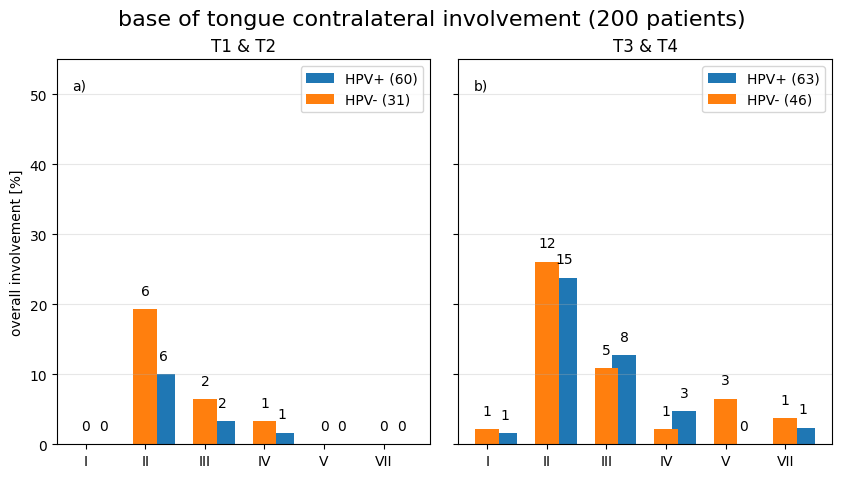


SUMMARY: CONTRALATERAL Lymph Node Involvement 
Diagnostic modality: max_llh
Split by: T-stage

Stage  HPV Level     n Percentage 95% CI
T1/T2 HPV+     I  0/60       0.0%    N/A
T1/T2 HPV-     I  0/31       0.0%    N/A
T1/T2 HPV+    II  6/60      10.0%    N/A
T1/T2 HPV-    II  6/31      19.4%    N/A
T1/T2 HPV+   III  2/60       3.3%    N/A
T1/T2 HPV-   III  2/31       6.5%    N/A
T1/T2 HPV+    IV  1/60       1.7%    N/A
T1/T2 HPV-    IV  1/30       3.3%    N/A
T1/T2 HPV+     V  0/60       0.0%    N/A
T1/T2 HPV-     V  0/30       0.0%    N/A
T1/T2 HPV+   VII  0/28       0.0%    N/A
T1/T2 HPV-   VII  0/12       0.0%    N/A
T3/T4 HPV+     I  1/63       1.6%    N/A
T3/T4 HPV-     I  1/46       2.2%    N/A
T3/T4 HPV+    II 15/63      23.8%    N/A
T3/T4 HPV-    II 12/46      26.1%    N/A
T3/T4 HPV+   III  8/63      12.7%    N/A
T3/T4 HPV-   III  5/46      10.9%    N/A
T3/T4 HPV+    IV  3/63       4.8%    N/A
T3/T4 HPV-    IV  1/46       2.2%    N/A
T3/T4 HPV+     V  0/63       0.0%    N/A
T3

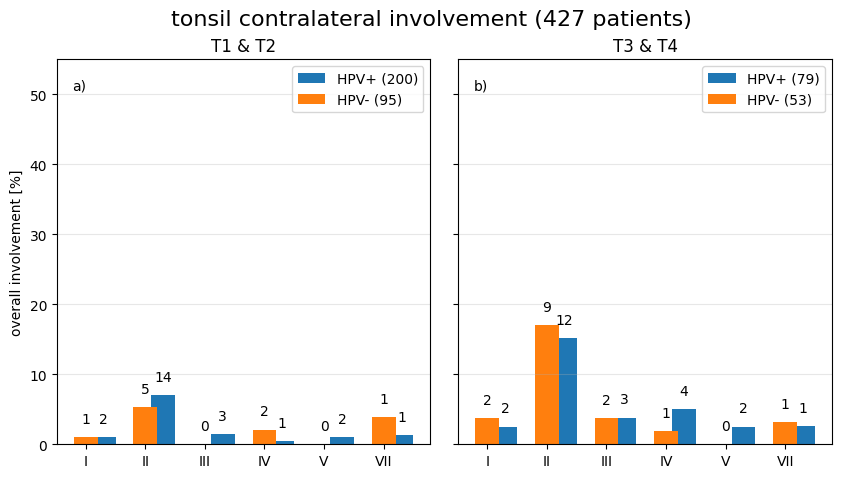


SUMMARY: CONTRALATERAL Lymph Node Involvement 
Diagnostic modality: max_llh
Split by: T-stage

Stage  HPV Level      n Percentage 95% CI
T1/T2 HPV+     I  2/200       1.0%    N/A
T1/T2 HPV-     I   1/95       1.1%    N/A
T1/T2 HPV+    II 14/200       7.0%    N/A
T1/T2 HPV-    II   5/95       5.3%    N/A
T1/T2 HPV+   III  3/200       1.5%    N/A
T1/T2 HPV-   III   0/95       0.0%    N/A
T1/T2 HPV+    IV  1/200       0.5%    N/A
T1/T2 HPV-    IV   2/95       2.1%    N/A
T1/T2 HPV+     V  2/200       1.0%    N/A
T1/T2 HPV-     V   0/95       0.0%    N/A
T1/T2 HPV+   VII   1/77       1.3%    N/A
T1/T2 HPV-   VII   1/26       3.8%    N/A
T3/T4 HPV+     I   2/79       2.5%    N/A
T3/T4 HPV-     I   2/53       3.8%    N/A
T3/T4 HPV+    II  12/79      15.2%    N/A
T3/T4 HPV-    II   9/53      17.0%    N/A
T3/T4 HPV+   III   3/79       3.8%    N/A
T3/T4 HPV-   III   2/53       3.8%    N/A
T3/T4 HPV+    IV   4/79       5.1%    N/A
T3/T4 HPV-    IV   1/53       1.9%    N/A
T3/T4 HPV+     V   2/7

,Stage,HPV,Level,n,Percentage,95% CI
0,T1/T2,HPV+,I,2/200,1.0%,N/A
1,T1/T2,HPV-,I,1/95,1.1%,N/A
2,T1/T2,HPV+,II,14/200,7.0%,N/A
3,T1/T2,HPV-,II,5/95,5.3%,N/A
4,T1/T2,HPV+,III,3/200,1.5%,N/A
5,T1/T2,HPV-,III,0/95,0.0%,N/A
6,T1/T2,HPV+,IV,1/200,0.5%,N/A
7,T1/T2,HPV-,IV,2/95,2.1%,N/A
8,T1/T2,HPV+,V,2/200,1.0%,N/A
9,T1/T2,HPV-,V,0/95,0.0%,N/A


In [55]:
involvement_plotter_HPV_with_CI(C01, 'max_llh', display = None, side='contra', show_ci = False, split_by = 't_stage',upper_limit = 55, title = 'base of tongue contralateral involvement (200 patients)')
involvement_plotter_HPV_with_CI(C09, 'max_llh', display = None, side='contra', show_ci = False, split_by = 't_stage',upper_limit = 55, title = 'tonsil contralateral involvement (427 patients)')
